# How similar is SARS-Cov-2 to other viruses?

Evolution is the process by which different living organisms are believed to have developed from earlier forms during the earth's history. The main component that evolves through time is the DNA which is passed on to the next generation. Genetic mutations, variation, and recombination are processes that modify DNA and cause variation in the population. The main drivers of evolution are natural selection and genetic drift that act on this variation. Through time, some characteristics become more common or rare in the population resulting in a change in heritable ones arising over successive generations.

Even though we do not consider viruses to be *living* organisms, they are still subject to evolution. Their genetic material undergoes the same transformations and selection, resulting in new variants and types of viruses.

<div>
    <img src="https://upload.wikimedia.org/wikipedia/commons/thumb/7/70/Phylogenetic_tree.svg/800px-Phylogenetic_tree.svg.png" width="500">
</div>

Image source: [Wikipedia](https://en.wikipedia.org/wiki/File:Phylogenetic_tree.svg)

Comparing the characteristics of different organisms allows us to estimate their evolutionary distance. We use genetic material as a proxy for these characteristics. We estimate evolutionary distance as the number of transformation events that would occur for one organism to become genetically identical. In practice, this means aligning genetic sequences and observing the number of transformation events. Performing multiple sequence alignment and calculating pairwise distances gives us a distance matrix.

One way of presenting the evolutionary distance between organisms is with a phylogenetic tree. Similar organisms are connected via their common ancestor, even though we do not have genetic data to prove their existence. However, these common ancestors likely existed in the past due to evolution. The most common algorithms for building phylogenetic trees are the UPGMA and Neighbor-Joining algorithms. Many frequentist and Bayesian variations of these are also available online.

Once we know the evolution of the virus, we can expand our knowledge about similar viruses to our virus of interest. Our task is implementing the neighbor-joining method, a plotting function, and constructing a phylogenetic tree of coronaviruses. In the last problem, we will see how recombination can seemingly contradict the flow of evolution.

#### Please ensure each answer is completed in the single cell of the notebook immediately following the question, and that all answers are in ```markdown``` format.

Once you have completed the notebook, make sure you save it and submit it via Moodle.

All questions are worth between 1 and 10 marks. There are a total of *40 marks* available in this workbook. There is one extra bonus problem for *10 marks*. 
  
Total notebook marks will be scaled to a **course mark out of 10** to contribute to your course total.

In [ ]:
import numpy as np
import pandas as pd
from Bio import Entrez

In [ ]:
# In order to import from the python file without hassle, we add the current
# directory to the python path
import sys; sys.path.append(".")

Let's let the nice folks at NCBI know who we are.

In [ ]:
Entrez.email = "hafsafahad@student.unsw.edu.au"

## Problem 1: Neighbor joining implementation

**Task:** Use the template `neighbor_joining` function in the file `helper_functions.py` and implement the neighbor-joining (NJ) algorithm for agglomerative phylogenetic clustering. Your implementation should return a `Node` object to construct a tree structure and return a root Node. Use provided classes and add code where needed. Stick to the provided structure and test your solution with added unit tests. Provided unit tests do not test the correctness of your implementation but only the structure of your output.

**Implementation requirement:** In theory, the neighbor-joining algorithm results in an unrooted tree. But for plotting and later rooting the tree, your implementation should return a root node. In the last iteration of the NJ, the algorithm joins the final two nodes by creating a root node and setting the distance to each of the remaining nodes as half of the distance between them.

(Optional) In problem 2, you will be implementing a plotting function for a phylogenetic tree. For easier visual comparison of the dendrograms, you can follow instructions in the function docstring to handle node additions and tie-breaks. Even if you handle tie-breaks differently, your implementation will be valid.

**[9 points]**

Answer the following question about the neighbour joining algorithm:
- What is one of the main differences of the neighbour joining algorithm compared to UPGMA? 

Store your answers in the `algorithm_diff` variable.

**[1 points]**.

In [ ]:
algorithm_diff = """
What is one of the main differences of the neighbour joining algorithm compared to UPGMA?
UPGMA assumes a molecular clock, meaning all lineages evolve at the same constant rate. 
That forces the tree to be ultrametric, with every leaf equally distant from the root. 
Neighbor joining makes no such assumption. It corrects each pairwise distance by the average 
distance of the two nodes to all other nodes, so lineages can evolve at different rates and 
branch lengths can differ. Because of this, NJ trees are unrooted unless an outgroup is used.
""" 

In [ ]:
from helper_functions import neighbor_joining
from helper_functions import Node 

## Problem 2: Plotting a phylogenetic tree

**Task:**
Use the template `plot_nj_tree` function in the file `helper_functions.py` to write a plotting function using the `matplotlib` library.
The only limitation is to use the template function and two required inputs. How you position a dendrogram, colour the plot, labels and everything else is up to you.

Leaves in a dendrogram are connected via horizontal and vertical lines. Horizontal lines represent genetic distance, while vertical ones present divergence of the last common ancestor. Below is an example of a dendrogram. Leaves do not align on a vertical line as with hierarchical clustering.

<div>
    <img src="https://upload.wikimedia.org/wikipedia/commons/d/dd/Phylogenetic_tree_of_coronaviruses.jpg" width="500">
</div>

*(Patrick C. Y. Woo, Yi Huang, Susanna K. P. Lau, and Kwok-Yung Yuen, [CC BY 3.0](https://creativecommons.org/licenses/by/3.0/deed.en) )*

Test your implementation to our provided unit tests by comparing your output plot to the ground truth in `tests/test_plotting_dendrogram.png`. Write your own tests as well.

**[10 points]**

In [ ]:
from helper_functions import plot_nj_tree

## Problem 3: Phylogenetic analysis of coronavirus

You obtained 31 aligned sequences of different coronaviruses collected at multiple time points worldwide. We used the Clustal algorithm to provide you with a multiple sequence alignment (MSA) file in `data/clustal_MSA_coronavirus.fasta`. Each entry has a form `name|accession`.

We will use Hamming distance to calculate genetic distance from pairwise sequence alignment. This naive approach estimates the distance by counting the number of mismatches in the alignment. For example, alignment *"ATC"* and *"ATT"* will have a distance of 1 while *"AT-C"* and *"CTTC"* will have a distance of 2. There are more sophisticated approaches to evolutionary distance estimation, but for our use case, Hamming distance will suffice.

Plot a phylogenetic tree of coronaviruses using your implementation of `neighbor_joining` and `plot_nj_tree`.
Compare your results to the ones found on [Wikipedia](https://en.wikipedia.org/wiki/Coronavirus). Note that three additional viruses in our alignment file do not appear in the figure.

You might notice your figure differs from the one on Wikipedia. Neighbor-joining results in an unrooted or poorly rooted tree at best. Biologists developed a clever approach to determine the root of a neighbor-joining tree by including one distant relative species in the alignment, called the outgroup. In the course of evolution, a distance relative diverged first. We can determine the midpoint between the outgroup and the rest of the phylogenetic tree as a root. This approach proclaims the root node as the last common ancestor between all species in the tree. We will be using the *Breda virus* as an outgroup.

Order in a dendrogram can give an impression of a nicer plot. We can achieve this by setting the left child as the one with fewer leaf nodes in a subtree.

As a final step, fetch NCBI annotations to determine their coronavirus group. Present those groupings on your figure with colors.

**Task:** Plot the most informative phylogenetic tree by iteratively improving your implementation.

**a)** Calculate pairwise distances of aligned sequences using Hamming distance.
Construct and plot the phylogeny dendrogram using your implementations of neighbor-joining and plotting algorithm in `helper_functions`. **[4 points]**

**b)** Reroot the tree using the provided `reroot_tree` function in the `helper_function`. Use it to reroot a tree using the *Breda virus* as an outgroup. You have to fetch an outgroup from the tree first, and then use the reroot function. If you added any other relational parameters to your `Node` class, make sure you adjust the function. **[+1 points]**

**c)** Implement `sort_children_by_leaves` function in the `helper_function`. Use it to sort child nodes by assigning a left child to the one with fewer leaf nodes in their subtree. **[+1 points]**

**d)** Use color and labeling to show four major groups of coronaviruses. You can find the type of coronavirus in the NCBI annotations under the *taxonomy* field. **[+1 points]**

Save your final figure as `problem3.svg`. Make sure you save the figure using `plt.savefig('problem3.svg')` to ensure the correct format.

**[7 points in total]**

Then answer the following questions about the phylogenetic tree you have just drawn:
- To which group does SARS-CoV-2 belong? Answer using only the group name.
- Which of the following organisms would still be a valid outgroup in our case, and why?
  - Munia coronavirus HKU13 
  - Transmissible gastroenteritis coronavirus (TGEV)
  - Turkey coronavirus (TCoV) 
- As described above, we used an outgroup to root our tree. Another way to root a tree is through "Midpoint rooting", where the root is positioned at the midpoint between the two longest branches. What assumption needs to hold for this approach to make sense? 

Save your answers in the variables `sars_cov_2_group`, `valid_outgroup_choice` and `phylogenetic_midroot` respectively.

**[3 points]**

In [3]:
%load_ext autoreload
%autoreload 2

31 sequences
(31, 31) symmetric: True zero diagonal: True


<Axes: xlabel='Genetic distance'>

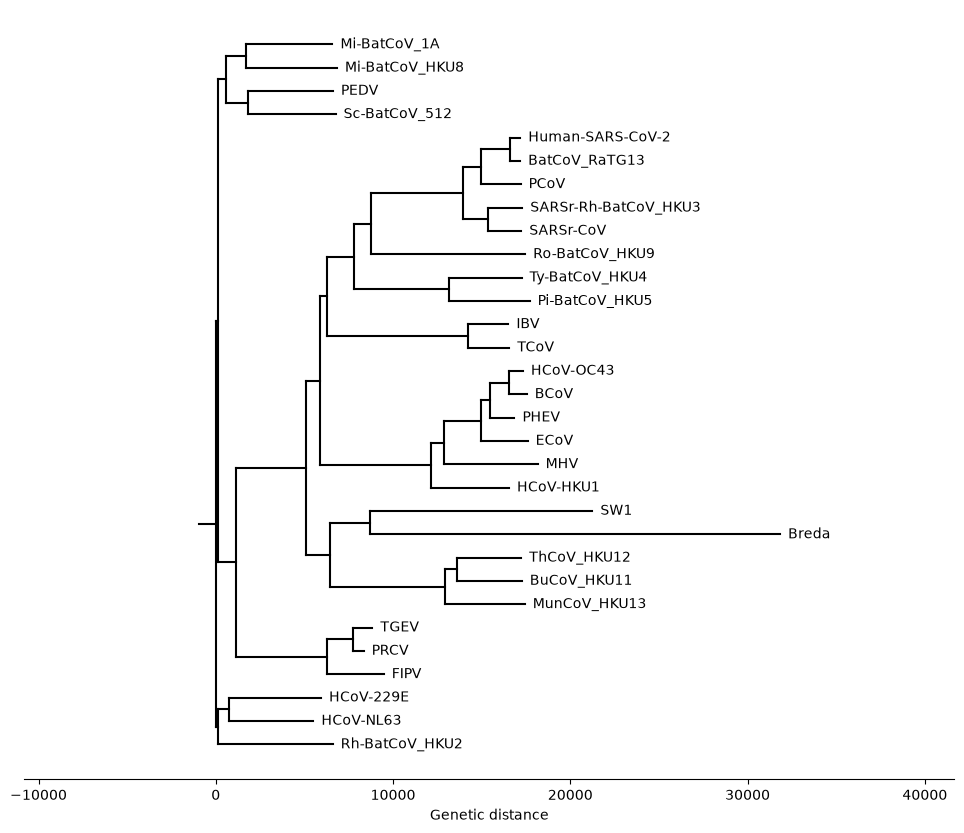

In [4]:
# 3a: read the alignment, work out distances, draw the first tree
import numpy as np
import matplotlib.pyplot as plt
from Bio import SeqIO
from helper_functions import (neighbor_joining, plot_nj_tree, reroot_tree,
                              sort_children_by_leaves, Node)
 
# Read the multiple sequence alignment (31 coronaviruses, already aligned,
# so every sequence is the same length)
records = list(SeqIO.parse("data/clustal_MSA_coronavirus.fasta", "fasta"))
 
# Each header looks like "name|accession". Split them so I have the name
# (used as the leaf label) and the accession (used later for the NCBI lookup)
names, accessions = [], []
for r in records:
    name, acc = r.description.split("|")[:2]
    names.append(name.strip())
    accessions.append(acc.strip())
print(len(names), "sequences")
 
# reroot_tree finds nodes by name, so names must be unique
assert len(set(names)) == len(names), "duplicate names"
 
# One row per sequence, one column per alignment position
arr = np.array([list(str(r.seq).upper()) for r in records])
 
# Hamming distance = number of positions where two sequences differ.
# Comparing arr[:, None, :] with arr[None, :, :] checks every pair at once,
# then sum(axis=2) counts the mismatches for each pair (a gap vs a base counts)
D = (arr[:, None, :] != arr[None, :, :]).sum(axis=2).astype(float)
 
# Sanity checks: a distance matrix should be symmetric with zeros on the diagonal
print(D.shape, "symmetric:", np.allclose(D, D.T), "zero diagonal:", np.all(np.diag(D) == 0))
 
# Build the tree with my neighbor joining and draw it (no rooting yet)
tree = neighbor_joining(D, names)
fig, ax = plt.subplots(figsize=(12, 10))
plot_nj_tree(tree, ax=ax)

31 leaves; well formed: True
outgroup depth from new root: 11561.15625


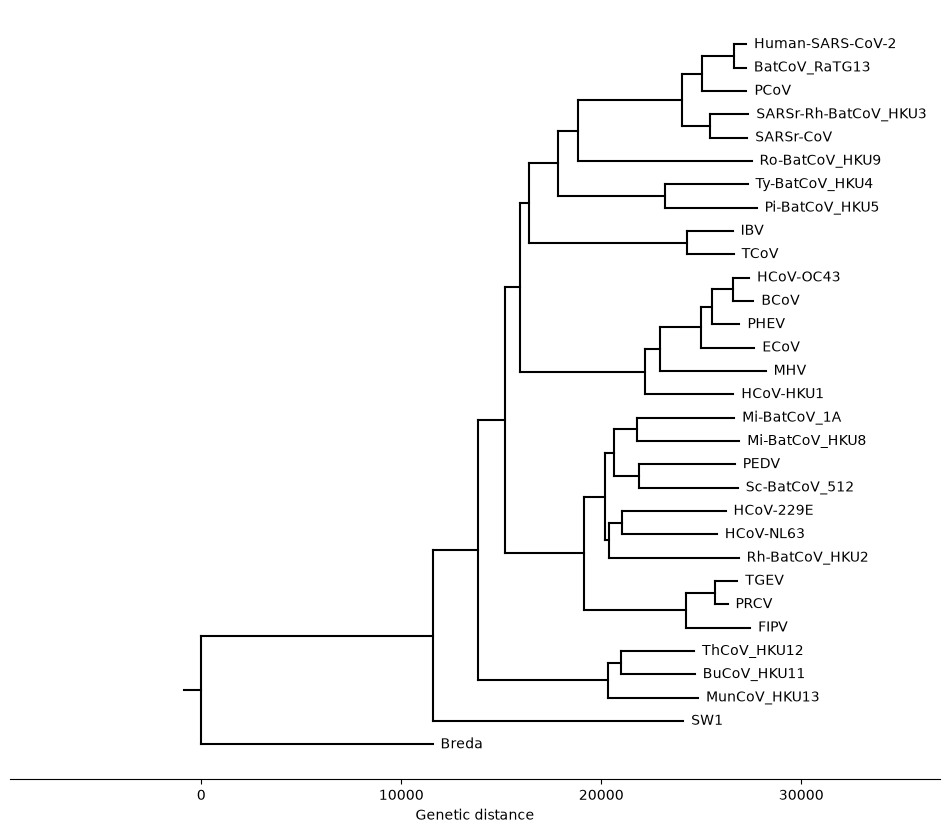

In [7]:
def find_node(node, name):
    """Search the tree for the node with this name (None if it isn't there)."""
    # Reached the end of a branch without finding it
    if node is None:
        return None
    # Found it
    if node.name == name:
        return node
    # Otherwise look in the left subtree, and if it isn't there, the right one
    return find_node(node.left, name) or find_node(node.right, name)


def leaf_depths(node, depth=0.0, out=None):
    """{leaf name: distance from this node}"""
    # The dictionary is created on the first call and passed down the recursion
    if out is None:
        out = {}
    # A leaf has no children, so record how far we have come to reach it
    if node.left is None and node.right is None:
        out[node.name] = depth
        return out
    # Go down both branches, adding each branch length to the running distance
    leaf_depths(node.left, depth + node.left_distance, out)
    leaf_depths(node.right, depth + node.right_distance, out)
    return out


def is_well_formed(node):
    """Every node is either a leaf (no children) or has BOTH children."""
    # A leaf is fine
    if node.left is None and node.right is None:
        return True
    # An internal node with only one child means rerooting broke the tree
    if node.left is None or node.right is None:
        return False
    # Otherwise both subtrees also have to be well formed
    return is_well_formed(node.left) and is_well_formed(node.right)


# Find the Breda virus in the list of names, then get its node from the tree
breda_name = [n for n in names if "Breda" in n][0]
outgroup = find_node(tree, breda_name)

# Move the root so that Breda is the outgroup (reroot_tree came with the template)
rerooted = reroot_tree(tree, outgroup)

# Checks: reroot_tree is a template function, so verify it behaved.
# All 31 leaves should still be there and no node should be missing a child
depths = leaf_depths(rerooted)
print(len(depths), "leaves; well formed:", is_well_formed(rerooted))
# Breda should be as far from the new root as half its original branch
print("outgroup depth from new root:", depths[breda_name])

# Put the child with fewer leaves on the left at every split (in place)
sort_children_by_leaves(rerooted)

# Draw the rerooted, sorted tree
fig, ax = plt.subplots(figsize=(12, 10))
plot_nj_tree(rerooted, ax=ax);

In [8]:
# 3d (part 1): get each virus's group from NCBI
import json, os, time
from Bio import Entrez
from matplotlib.patches import Patch
 
Entrez.email = "hafsafahad@student.unsw.edu.au"   # NCBI asks for an email address
 
# Save the NCBI results in a file so I only download them once
cache_file = "taxonomy_cache.json"
cache = json.load(open(cache_file)) if os.path.exists(cache_file) else {}
 
for acc in accessions:
    if acc not in cache:
        # Download the GenBank record; its annotations contain the taxonomy list
        with Entrez.efetch(db="nuccore", id=acc, rettype="gb", retmode="text") as h:
            rec = SeqIO.read(h, "genbank")
        cache[acc] = rec.annotations["taxonomy"]
        time.sleep(0.4)   # NCBI only allows about 3 requests per second
json.dump(cache, open(cache_file, "w"))
 
# The four coronavirus groups we want to show
GROUPS = ["Alphacoronavirus", "Betacoronavirus", "Gammacoronavirus", "Deltacoronavirus"]
 
 
def get_group(lineage):
    """Pick the group name out of the taxonomy list. Breda virus isn't a
    coronavirus, so it ends up in the "other" group."""
    return next((t for t in lineage if t in GROUPS), "Outgroup / other")
 
 
groups = {n: get_group(cache[a]) for n, a in zip(names, accessions)}
 
# Print each group's members to check them against the Wikipedia figure
for g in GROUPS + ["Outgroup / other"]:
    print(g, [n for n, grp in groups.items() if grp == g])

Alphacoronavirus ['FIPV', 'PRCV', 'TGEV', 'Sc-BatCoV_512', 'PEDV', 'Mi-BatCoV_HKU8', 'Mi-BatCoV_1A', 'Rh-BatCoV_HKU2', 'HCoV-NL63', 'HCoV-229E']
Betacoronavirus ['MHV', 'HCoV-HKU1', 'ECoV', 'BCoV', 'HCoV-OC43', 'PHEV', 'Pi-BatCoV_HKU5', 'Ty-BatCoV_HKU4', 'Ro-BatCoV_HKU9', 'SARSr-CoV', 'SARSr-Rh-BatCoV_HKU3', 'PCoV', 'BatCoV_RaTG13', 'Human-SARS-CoV-2']
Gammacoronavirus ['SW1', 'TCoV', 'IBV']
Deltacoronavirus ['MunCoV_HKU13', 'BuCoV_HKU11', 'ThCoV_HKU12']
Outgroup / other ['Breda']


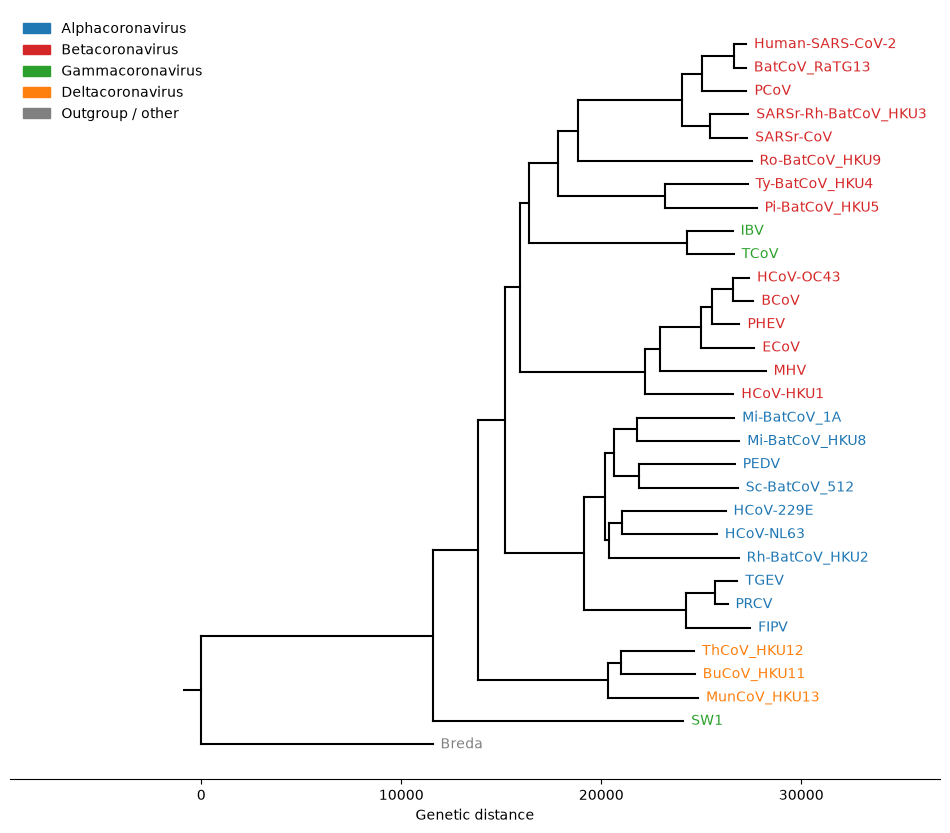

In [9]:
# 3d (part 2): colour the leaves by group and save the figure
palette = {"Alphacoronavirus": "tab:blue", "Betacoronavirus": "tab:red",
           "Gammacoronavirus": "tab:green", "Deltacoronavirus": "tab:orange",
           "Outgroup / other": "gray"}
 
# leaf name -> colour, which plot_nj_tree uses for the labels
leaf_colors = {n: palette[g] for n, g in groups.items()}
 
fig, ax = plt.subplots(figsize=(12, 10))
plot_nj_tree(rerooted, ax=ax, leaf_colors=leaf_colors)
 
# Legend showing which colour is which group
ax.legend(handles=[Patch(color=c, label=g) for g, c in palette.items()],
          loc="upper left", frameon=False)
 
# Save in the same cell as the plot so the right figure is saved
plt.savefig("problem3.svg")
 

In [ ]:
sars_cov_2_group = """To which group does SARS-CoV-2 belong? Answer using only the group name.
Betacoronavirus"""

In [ ]:
valid_outgroup_choice = """Which of the following organisms would still be a valid outgroup in our case, and why?
Munia coronavirus HKU13 (a Deltacoronavirus). A valid outgroup must have diverged before the last common ancestor
of the rest of the tree, so that it is more distant from every ingroup virus than they are from each other. In our
rooted tree the Deltacoronaviruses branch off early, close to the root next to Breda, so rooting on Munia would still
place the root near the base of the tree and keep the Alpha and Beta groups together. TGEV is an Alphacoronavirus
nested inside the Alpha clade, and TCoV groups with the Beta-side clade, so rooting on either would split a group and
place the root inside the ingroup"""

In [ ]:
phylogenetic_midroot = """What assumption needs to hold for the midpoint rooting approach to make sense?
The molecular clock assumption: all lineages must evolve at approximately the same, constant rate, so that
branch length is proportional to time. Only then are the two most distant taxa equally far from the true root,
and the midpoint of the longest path is the root. If rates differ between lineages (for example one lineage evolving much faster),
the longest branches reflect rate differences and the midpoint will not be the true root.
"""

## Problem 4: Recombination

We tend to think of evolution as a hierarchical process: we have some common ancestor that split into several sub-species through a series of random mutations. However, nothing is that straightforward in biology. There have been well-documented cases of horizontal gene transfer in nature where organisms swap entire chunks of DNA with each other. In viruses, something similar can happen as well. When a cell is infected with multiple virions (potentially different strains of the same virus), a *recombination event* can occur. Recombination occurs during the DNA copying process when, for whatever reason, the copier swaps out the virus template midway with a different template. For instance, we could start copying virus A, and then midway, the copier will switch to virus B, effectively resulting in new virus DNA that has DNA from both viruses A and B.

During the start of the global pandemic, there was much confusion about the origins of SARS-CoV-2. We initially thought it came from bats. Then, at some point, people noticed that a critical piece of the spike protein -- the receptor binding domain (RBD) -- was more similar to the sequence of pangolin coronaviruses. This evidence points to recombination. Before the virus jumped to humans, there must have been some host infected with both the Bat RaTG13 coronavirus and the Pangolin coronavirus where this recombination happened.

In this problem, we will look at the spike protein, look at the receptor binding domain, and check this evidence for recombination ourselves.

**Task**:
Find the spike proteins of the three viruses and align the sequences with each other using your global alignment implementation from the previous assignment. Since we're comparing the differences between the bat and pangolin coronaviruses to the human virus, we only need to compute two alignments: human to bat and human to pangolin. We will then compare the differences between the two alignments. Find the RBD of SARS-CoV-2  using the [NCBI graphical view of the SARS-CoV-2 genome](https://www.ncbi.nlm.nih.gov/projects/sviewer/?id=NC_045512&tracks=[key:sequence_track,name:Sequence,display_name:Sequence,id:STD649220238,annots:Sequence,ShowLabel:false,ColorGaps:false,shown:true,order:1][key:gene_model_track,name:Genes,display_name:Genes,id:STD3194982005,annots:Unnamed,Options:ShowAllButGenes,CDSProductFeats:true,NtRuler:true,AaRuler:true,HighlightMode:2,ShowLabel:true,shown:true,order:9]&v=1:29903&c=null&select=null&slim=0) and look at the aminoacid similarity inside and outside the RBD. Similarly to the original publication, we will use a sliding window approach to calculate the similarity between sequences. Calculate the average number of matching amino acids for each window location in the alignment and plot the resulting similarity sequence. A window size of 100 is a good starting point. Perform this sliding window approach for both alignments and plot both similarity sequences in a single figure. Which coronavirus is more similar to SARS-CoV-2 in the RBD, and which is more similar outside the RBD? Create a visualization similar to the one in Fig. 2a from [the original Nature paper](https://www.nature.com/articles/s41586-020-2169-0)
to compare the human-to-bat and the human-to-pangolin alignments. Make sure to do this for the whole genome, not just the spike region. But also include a second plot with just the spike region to help answer the following questions. 

Save your visualisation to `recombination.svg`. Make sure you save the figure using `plt.savefig('recombination.svg')` to ensure the correct format.

**[8 points]**

Then answer the following questions about recombination:
- Which coronavirus is more similar to SARS-CoV-2 inside the RBD and which is more similar outside the RBD? How did you observe this from a plot?
- Looking at your visualisation, are there other regions in the spike or in the genome that could be due to recombination? Could there be an alternative explanation for the differences in these regions?


Save your answers in the variables `recombination_inside_rbd` and `recombination_other_regions` respectively.

**[2 points]**

In [10]:
accession_codes = {
    "Human-SARS-CoV-2": "NC_045512",
    "Bat-CoV RaTG13": "MN996532",
    "Pangolin-CoV MP789": "MT121216",
}

In [ ]:
# Load global_alignment from helper_functions.py
import importlib, helper_functions
importlib.reload(helper_functions)   # make sure I'm using the latest saved version
from helper_functions import global_alignment

In [11]:
# Download the three genomes from NCBI and pull out the spike protein of each
from Bio import Entrez, SeqIO
import time
 
 
def fetch_record(acc):
    """Download one GenBank record from NCBI."""
    with Entrez.efetch(db="nuccore", id=acc, rettype="gb", retmode="text") as h:
        return SeqIO.read(h, "genbank")
 
 
records4 = {}
for label, acc in accession_codes.items():
    records4[label] = fetch_record(acc)
    time.sleep(0.4)   # stay under NCBI's request limit
 
 
def get_spike(rec):
    """Return the amino acid sequence of the spike protein of a record."""
    for f in rec.features:
        # Only the CDS (protein coding) features have a translation
        if f.type != "CDS":
            continue
        # The spike can be labelled "surface glycoprotein", "spike" or gene "S"
        text = " ".join(f.qualifiers.get("product", []) + f.qualifiers.get("gene", [])).lower()
        if "surface glycoprotein" in text or "spike" in text or f.qualifiers.get("gene", [""])[0] == "S":
            return f.qualifiers["translation"][0]
    raise ValueError(f"no spike CDS found in {rec.id}")
 
 
spikes = {label: get_spike(rec) for label, rec in records4.items()}
# Check the lengths: they should all be roughly 1,270 amino acids
for label, s in spikes.items():
    print(label, len(s))

Human-SARS-CoV-2 1273
Bat-CoV RaTG13 1269
Pangolin-CoV MP789 1265


In [12]:
# Align the human spike to the bat spike and to the pangolin spike
from helper_functions import global_alignment
from Bio.Align import substitution_matrices
 
# BLOSUM62 gives each pair of amino acids a score (similar ones score higher)
blosum = substitution_matrices.load("BLOSUM62")
GAP = -4   # every gap position costs 4 (a linear gap penalty)
# Turn the matrix into a dictionary so each lookup is quick
score_table = {(a, b): float(blosum[a, b]) for a in blosum.alphabet for b in blosum.alphabet}
 
 
def protein_score(x, y):
    """Score for aligning two characters, which is what global_alignment expects."""
    if x == "-" or y == "-":
        return GAP
    return score_table[(x, y)]
 
 
human = spikes["Human-SARS-CoV-2"]
# Each call returns the two aligned strings and the alignment score
h_bat, bat, score_bat = global_alignment(human, spikes["Bat-CoV RaTG13"], protein_score)
h_pan, pan, score_pan = global_alignment(human, spikes["Pangolin-CoV MP789"], protein_score)
print(len(h_bat), len(h_pan), score_bat, score_pan)

1273 1276 6539.0 6085.0


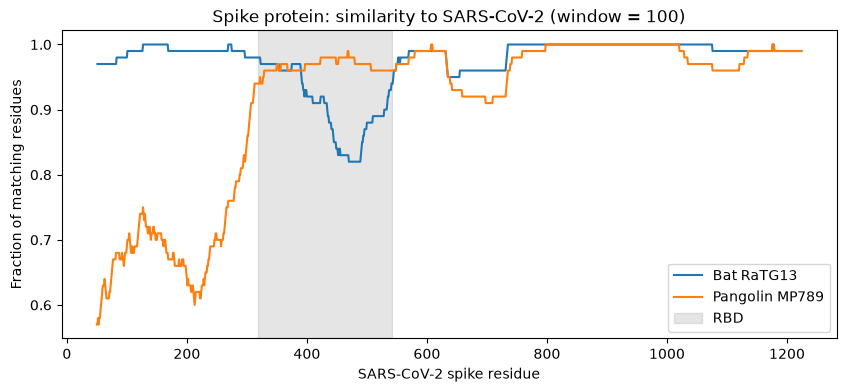

In [13]:
#Sliding window similarity for the spike protein, plus the first plot
import numpy as np
import matplotlib.pyplot as plt
 
 
def similarity_track(aln_ref, aln_other, window=100):
    """Fraction of matching (non-gap) columns in a sliding window,
    plotted against the reference (human) residue number."""
    # 1 where both sequences have the same letter (and it isn't a gap), else 0
    match = np.array([(x == y and x != "-") for x, y in zip(aln_ref, aln_other)], float)
    # Averaging the 0/1 values in every window of `window` columns
    sim = np.convolve(match, np.ones(window) / window, mode="valid")
    # Alignment columns include gaps, so convert each column to the
    # human residue number it corresponds to
    ref_pos = np.cumsum([c != "-" for c in aln_ref])
    # Plot each window at its middle position
    centres = ref_pos[window // 2 : window // 2 + len(sim)]
    return centres, sim
 
 
x_bat, s_bat = similarity_track(h_bat, bat)
x_pan, s_pan = similarity_track(h_pan, pan)
 
 
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x_bat, s_bat, label="Bat RaTG13")
ax.plot(x_pan, s_pan, label="Pangolin MP789")
# Shade the RBD (residues 319-541 of the spike)
ax.axvspan(319, 541, color="gray", alpha=0.2, label="RBD")
ax.set_xlabel("SARS-CoV-2 spike residue")
ax.set_ylabel("Fraction of matching residues")
ax.set_title("Spike protein: similarity to SARS-CoV-2 (window = 100)")
ax.legend()

In [ ]:
recombination_inside_rbd = """
Which coronavirus is more similar to SARS-CoV-2 inside the RBD and which is more similar outside the RBD?
"""

In [ ]:
recombination_other_regions = """
Looking at your visualisation, are there other regions in the genome (or still in the spike region) that could be due to recombination?
"""

## Bonus 1: Bootstrap confidence

We performed an alignement, calulated pairwise distances and built a phylogenetic tree. Are we confident in our phylogenetic tree? The answer is, we don't know, because we never estimated the uncertainty of our solution.

In 1985, Joseph Felsenstein wrote an [article](https://pubmed.ncbi.nlm.nih.gov/28561359/) on estimating confidence limits of phylogenetic trees using a non-parametric bootstrap. It stands from the idea of creating bootstrap versions of alignment and building alternative phylogenetic trees. A confidence in a clade is then represented as a proportion of alternative trees that contain the same clade.

To generate a bootstrap version of alignment with length $N$, we sample $N$ alignment positions with replacement. Rearanging sequences accoring to a sequence of sampled indicies give us an alternative alignment. Based on new alignment we calculate the distance and apply neighbor joining algorithm to get an alternative tree.

Here we define a clade equivalence:
*Let $L$ be a set of leaf nodes in a clade from original tree and $L'$ be a set of leaf nodes in a clade from alternative tree. Let $L_1$ and $L_2$ be sets of leaf nodes of both children of a clade, such that $L = L_1 \bigcup L_2$. A clade of an alternative tree is considered the same if and only if $L = L'$ and ( $L_1 \bigcap L_1' = \emptyset\;\land\;L_2 \bigcap L_2'=\emptyset$ or $L_1 \bigcap L_2' = \emptyset\;\land\;L_2 \bigcap L_1'=\emptyset$ ).*

You are now given a Clustal mutliple sequence alignment of spike proteins from the same coronavirses as before. The alignment is store in `data/clustal_MSA_coronavirus_spike.fasta`. Again use Hamming distance for calculating distance and Breda virus as an outgroup.

**Task:** Construct a phylogenetic tree from spike protein MSA and use the bootstrap method for estimating confidence of each clade. Plot the phylogenetic tree and add confidence estimates on the plot.

**a)** Construct 100 alternative trees from bootstraped coronavirus alignments. Make sure you root your trees before estimating confidence.

**b)** Write a function to find a clade from the original tree in an alternative tree.

**c)** Calculate and asign confidence value of a clade to an attribute `Node.confidence`. Note that leaf nodes always have confidence 1.

**d)** Plot the phylogeny tree with confidence estimates using the same plotting function `plot_nj_tree` as in Problem 3. Do not plot confidence of leaf nodes.

Save your plot into `confidence_tree.svg`. Make sure you save the figure using `plt.savefig('confidence_tree.svg')` to ensure the correct format.

**[9 points]**

Then answer the following question:
- How does the phylogenetic tree compare to the one from Problem 3? Which part of the phylogenetic tree are we the least confident in?

Store your answers in the `bootstrap_comparison` variable.


**[1 points]**

In [ ]:
bootstrap_comparison = """
How does the phylogenetic tree compare to the one from Problem 3? Which part of the phylogenetic tree are we the least confident in?
"""